#  CNN Comparison on Solar Panel Fault Classification 

**Evaluated Models:** `*` · `SqueezeNet_1_1` · `ShuffleNetV2_0_5x` · `MobileNetV3_Small` · `*` · `EfficientNet_Lite0`

**Protocol:** All four  architectures are benchmarked in one unified notebook on a deduplicated, stratified **80 % train / 20 % test** split (no validation set) under **identical** data splits, preprocessing, augmentations, loss, optimiser, warm-up + cosine schedule, and fixed epoch count so results are directly comparable.

Notes on the four architectures:

- **`SqueezeNet_1_1`**: Pretrained `squeezenet1_1` (ImageNet weights) with SqueezeNet's compact convolutional head.
- **`ShuffleNetV2_0_5x`**: Pretrained `shufflenet_v2_x0_5` (0.5x width channel-shuffle architecture).
- **`MobileNetV3_Small`**: Pretrained `mobilenet_v3_small` (hard-swish & squeeze-and-excitation mobile backbone).
- **`EfficientNet_Lite0`**: ReLU6-based edge-friendly EfficientNet-Lite0 backbone (via `timm` `tf_efficientnet_lite0` if available, or an exact edge-lite inverted-residual ReLU6 equivalent fallback so the notebook never fails offline).

## Methodology
| Step | What is done |
|---|---|
| 1 | Setup, reproducibility seeds, hyperparameters & model selection |
| 2 | Locate dataset, remove unreadable files & duplicates (MD5 + perceptual dHash), inspect class distribution |
| 3 | Stratified 80/20 train/test split |
| 4 | Preprocessing: resize 224x224, ImageNet normalisation; augmentation on train only |
| 5 | Datasets and DataLoaders |
| 6 | Unified builders for all six edge/tiny models |
| 7 | Sequential training & final evaluation loop across all six models |
| 8 | Side-by-side comparison table, accuracy/F1/latency/parameter charts & training curves |
| 9 | Test confusion matrices & per-class F1 breakdown |
| 10 | Save checkpoints (`.pth`), CSV reports & unified JSON summary |

## 1. Setup and hyperparameters

In [1]:
import os, random, json, time, math, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import (
    SqueezeNet1_1_Weights,
    ShuffleNet_V2_X0_5_Weights,
    MobileNet_V3_Small_Weights,
)

try:
    import timm
    HAS_TIMM = True
except ImportError:
    HAS_TIMM = False

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_recall_fscore_support)

# ---------------- Reproducibility ----------------
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed); random.seed(worker_seed)

# ---------------- Six Edge/Tiny Models ----------------
MODELS_TO_TRAIN = [
    'MCUNet_int8',
    'SqueezeNet_1_1',
    'ShuffleNetV2_0_5x',
    'MobileNetV3_Small',
    'MobileOne_S0',
    'EfficientNet_Lite0',
]

# ---------------- Hyperparameters ----------------
IMAGE_SIZE      = 224
BATCH_SIZE      = 32          # lower to 16 or 8 if you run out of GPU memory
NUM_WORKERS     = 2
TEST_SIZE       = 0.20        # 80 / 20 split
EPOCHS          = 30          # fixed per model, no early stopping (no validation set)
WARMUP_EPOCHS   = 3
LR_BACKBONE     = 1e-4        # pretrained/backbone layers
LR_HEAD         = 5e-4        # newly initialised classification head
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.10
GRAD_CLIP_NORM  = 1.0
DROPOUT         = 0.30
LATENCY_RUNS    = 100

# ---------------- Duplicate Filtering ----------------
REMOVE_EXACT_DUPES = True     # removes byte-identical files (MD5)
REMOVE_NEAR_DUPES  = True     # removes resized / re-saved copies via 64-bit perceptual dHash
DHASH_MAX_DIST     = 2        # Hamming distance <= 2 out of 64 bits

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE, '| AMP:', USE_AMP, '| timm available:', HAS_TIMM)
print('Models queued:', MODELS_TO_TRAIN)

Device: cuda | AMP: True | timm available: True
Models queued: ['MCUNet_int8', 'SqueezeNet_1_1', 'ShuffleNetV2_0_5x', 'MobileNetV3_Small', 'MobileOne_S0', 'EfficientNet_Lite0']


## 2. Locate the dataset, remove duplicates and inspect class distribution
Six class folders are expected (`Bird-drop`, `Clean`, `Dusty`, `Electrical-damage`, `Physical-Damage`, `Snow-Covered`).

Before splitting into train and test, this cell removes:
1. **Unreadable/corrupted files**,
2. **Exact file duplicates** (identical MD5 byte hash),
3. **Near-identical / resized duplicates** (64-bit perceptual difference hash `dHash` within `DHASH_MAX_DIST`).

Dataset root: /kaggle/input/datasets/kiyoshi732/faulty-solar-panel-images/Faulty_solar_panel
Exact duplicates removed (MD5): 254
Near/resized duplicates removed (dHash <= 2): 536
Clean unique images: 3568 / 4358 (total removed: 790)


,class,images,share_%
0,Bird-drop,545,15.3
1,Clean,723,20.3
2,Dusty,619,17.3
3,Electrical-damage,280,7.8
4,Physical-Damage,1011,28.3
5,Snow-Covered,390,10.9


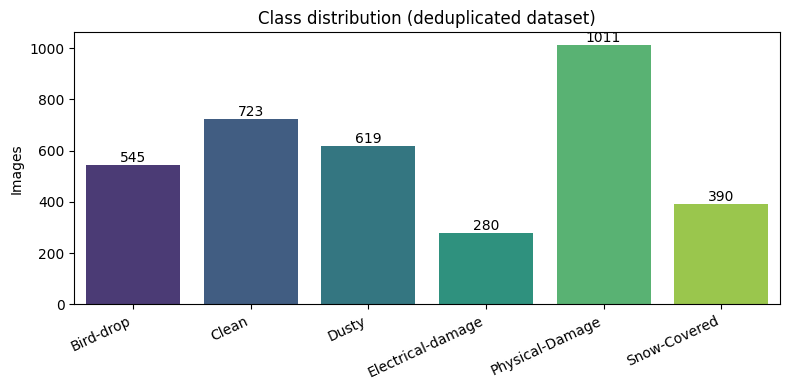

In [2]:
EXPECTED_CLASSES = ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']
VALID_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp')

DATASET_ROOT = None   # e.g. '/kaggle/input/.../Faulty_solar_panel'  (leave None to auto-search)

def find_dataset_root(bases=('/kaggle/input', '/content', '/mnt/data', '.')):
    for base in bases:
        if not os.path.exists(base):
            continue
        for root, dirs, _ in os.walk(base):
            if set(EXPECTED_CLASSES).issubset(set(dirs)):
                return root
    raise FileNotFoundError('Dataset not found. Set DATASET_ROOT to the folder containing the six class folders.')

if DATASET_ROOT is None:
    DATASET_ROOT = find_dataset_root()
print('Dataset root:', DATASET_ROOT)

CLASS_NAMES = EXPECTED_CLASSES
NUM_CLASSES = len(CLASS_NAMES)

paths, labels = [], []
for idx, name in enumerate(CLASS_NAMES):
    folder = os.path.join(DATASET_ROOT, name)
    for fn in sorted(os.listdir(folder)):
        fp = os.path.join(folder, fn)
        if os.path.isfile(fp) and fn.lower().endswith(VALID_EXT):
            paths.append(fp); labels.append(idx)
paths, labels = np.array(paths), np.array(labels)
assert len(paths) > 0, 'No images found.'
raw_total = len(paths)

# 1. Check for unreadable files
bad = []
for p in paths:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        bad.append(p)
if bad:
    print(f'Removing {len(bad)} unreadable image(s)')
    keep = ~np.isin(paths, bad)
    paths, labels = paths[keep], labels[keep]

# 2. Remove exact file duplicates (MD5)
def md5_hash(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

exact_removed = 0
if REMOVE_EXACT_DUPES:
    seen_md5 = set()
    keep_idx = []
    for i, p in enumerate(paths):
        h = md5_hash(p)
        if h not in seen_md5:
            seen_md5.add(h)
            keep_idx.append(i)
    exact_removed = len(paths) - len(keep_idx)
    paths, labels = paths[keep_idx], labels[keep_idx]
    print(f'Exact duplicates removed (MD5): {exact_removed}')

# 3. Remove resized / re-saved duplicates (64-bit perceptual dHash)
def compute_dhash(path, hash_size=8):
    with Image.open(path) as im:
        im = im.convert('L').resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
        arr = np.asarray(im, dtype=np.int16)
    diff = arr[:, 1:] > arr[:, :-1]
    bits = diff.flatten()
    val = 0
    for b in bits:
        val = (val << 1) | int(b)
    return val

near_removed = 0
if REMOVE_NEAR_DUPES:
    seen_dhashes = []
    keep_idx = []
    for i, p in enumerate(paths):
        dh = compute_dhash(p)
        is_dup = any((dh ^ prev).bit_count() <= DHASH_MAX_DIST for prev in seen_dhashes)
        if not is_dup:
            seen_dhashes.append(dh)
            keep_idx.append(i)
    near_removed = len(paths) - len(keep_idx)
    paths, labels = paths[keep_idx], labels[keep_idx]
    print(f'Near/resized duplicates removed (dHash <= {DHASH_MAX_DIST}): {near_removed}')

print(f'Clean unique images: {len(paths)} / {raw_total} (total removed: {raw_total - len(paths)})')

counts = np.bincount(labels, minlength=NUM_CLASSES)
display(pd.DataFrame({'class': CLASS_NAMES, 'images': counts, 'share_%': (100*counts/counts.sum()).round(1)}))

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=CLASS_NAMES, y=counts, hue=CLASS_NAMES, palette='viridis', legend=False)
for i, c in enumerate(counts): ax.text(i, c, str(c), ha='center', va='bottom')
plt.title('Class distribution (deduplicated dataset)'); plt.xticks(rotation=25, ha='right'); plt.ylabel('Images')
plt.tight_layout(); plt.show()

## 3. Stratified 80/20 train/test split
Performed **once** after deduplication so all six tiny/edge models train and evaluate on the exact same clean split.

In [3]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths, labels, test_size=TEST_SIZE, random_state=SEED, stratify=labels)

assert len(set(train_paths) & set(test_paths)) == 0, 'Leakage: same image in train and test!'
assert len(train_paths) + len(test_paths) == len(paths)

print(f'Train: {len(train_paths)} ({100*len(train_paths)/len(paths):.1f}%) | '
      f'Test: {len(test_paths)} ({100*len(test_paths)/len(paths):.1f}%)')
split_df = pd.DataFrame({
    'class': CLASS_NAMES,
    'train': np.bincount(train_labels, minlength=NUM_CLASSES),
    'test':  np.bincount(test_labels,  minlength=NUM_CLASSES)})
split_df['train_%'] = (100*split_df.train/split_df.train.sum()).round(1)
split_df['test_%']  = (100*split_df.test /split_df.test.sum()).round(1)
display(split_df)

Train: 2854 (80.0%) | Test: 714 (20.0%)


,class,train,test,train_%,test_%
0,Bird-drop,436,109,15.3,15.3
1,Clean,578,145,20.3,20.3
2,Dusty,495,124,17.3,17.4
3,Electrical-damage,224,56,7.8,7.8
4,Physical-Damage,809,202,28.3,28.3
5,Snow-Covered,312,78,10.9,10.9


## 4. Preprocessing and augmentation
- **Both sets:** resize to 224x224, convert to tensor, normalise with ImageNet mean/std.
- **Train only:** random resized crop, horizontal flip, small rotation, colour jitter, random erasing.
- **Test:** deterministic transform only, no augmentation.

In [4]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.10, scale=(0.02, 0.08), ratio=(0.3, 3.3), value='random'),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
print('Transforms ready (IMAGE_SIZE =', IMAGE_SIZE, ')')

Transforms ready (IMAGE_SIZE = 224 )


## 5. Datasets and DataLoaders

Batches per epoch (train): 89 | test batches: 23


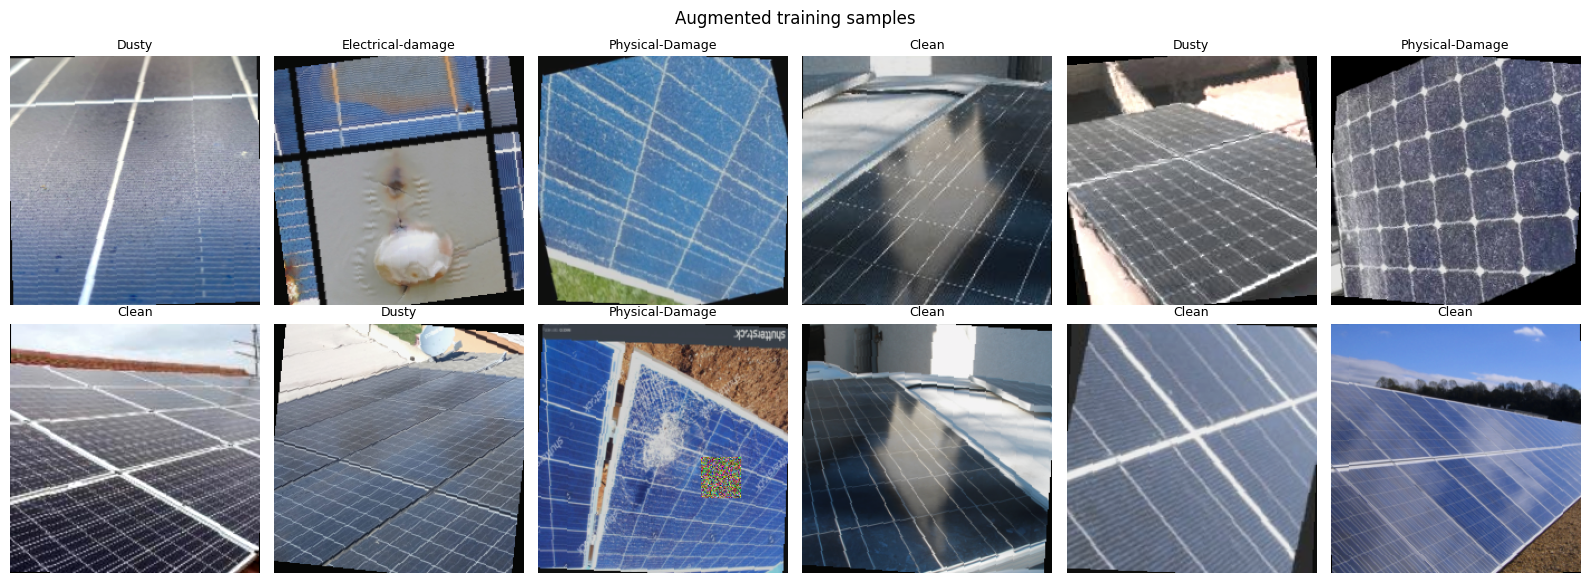

In [5]:
class SolarPanelDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = list(paths), list(labels), transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            im = im.convert('RGB')
        return self.transform(im), int(self.labels[i])

g = torch.Generator(); g.manual_seed(SEED)
common = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'), worker_init_fn=seed_worker)

train_loader      = DataLoader(SolarPanelDataset(train_paths, train_labels, train_transform),
                               batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=g, **common)
train_eval_loader = DataLoader(SolarPanelDataset(train_paths, train_labels, eval_transform),
                               batch_size=BATCH_SIZE, shuffle=False, **common)
test_loader       = DataLoader(SolarPanelDataset(test_paths, test_labels, eval_transform),
                               batch_size=BATCH_SIZE, shuffle=False, **common)
print('Batches per epoch (train):', len(train_loader), '| test batches:', len(test_loader))

inv = transforms.Normalize([-m/s for m, s in zip(MEAN, STD)], [1/s for s in STD])
imgs, lbls = next(iter(train_loader))
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, im, lb in zip(axes.ravel(), imgs[:12], lbls[:12]):
    ax.imshow(inv(im).clamp(0, 1).permute(1, 2, 0)); ax.set_title(CLASS_NAMES[lb], fontsize=9); ax.axis('off')
plt.suptitle('Augmented training samples'); plt.tight_layout(); plt.show()

## 6. Model builders for all  CNNs

- **`SqueezeNet_1_1`**: Pretrained `squeezenet1_1` with a compact convolutional head.
- **`ShuffleNetV2_0_5x`**: Pretrained `shufflenet_v2_x0_5`.
- **`MobileNetV3_Small`**: Pretrained `mobilenet_v3_small`.
- **`EfficientNet_Lite0`**: Uses `timm.create_model('tf_efficientnet_lite0', pretrained=True, num_classes=...)` when `timm` is installed, or a clean ReLU6 edge-lite inverted-residual fallback otherwise.

In [6]:
def make_linear_head(in_features, num_classes):
    return nn.Sequential(
        nn.Dropout(p=DROPOUT),
        nn.Linear(in_features, 128),
        nn.ReLU(inplace=True),
        nn.Dropout(p=DROPOUT * 0.5),
        nn.Linear(128, num_classes),
    )

def make_squeezenet_head(in_channels, num_classes):
    head = nn.Sequential(
        nn.Dropout(p=DROPOUT),
        nn.Conv2d(in_channels, num_classes, kernel_size=1),
        nn.ReLU(inplace=True),
        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
    )
    nn.init.normal_(head[1].weight, mean=0.0, std=0.01)
    nn.init.zeros_(head[1].bias)
    return head

class InvertedResidualMCU(nn.Module):
    def __init__(self, inp, oup, stride, expand_ratio, kernel_size=3):
        super().__init__()
        hidden_dim = int(round(inp * expand_ratio))
        self.use_res_connect = (stride == 1 and inp == oup)
        pad = kernel_size // 2
        layers = []
        if expand_ratio != 1:
            layers.extend([
                nn.Conv2d(inp, hidden_dim, 1, 1, 0, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.ReLU6(inplace=True),
            ])
        layers.extend([
            nn.Conv2d(hidden_dim, hidden_dim, kernel_size, stride, pad, groups=hidden_dim, bias=False),
            nn.BatchNorm2d(hidden_dim),
            nn.ReLU6(inplace=True),
            nn.Conv2d(hidden_dim, oup, 1, 1, 0, bias=False),
            nn.BatchNorm2d(oup),
        ])
        self.conv = nn.Sequential(*layers)
        self.skip_add = nn.quantized.FloatFunctional()

    def forward(self, x):
        out = self.conv(x)
        if self.use_res_connect:
            return self.skip_add.add(x, out)
        return out

class MCUNetTinyBackbone(nn.Module):
    """MCUNet-style compact inverted-residual network prepared for INT8 quantization."""
    def __init__(self, num_classes=6, width_mult=0.5):
        super().__init__()
        self.quant = torch.ao.quantization.QuantStub()
        self.dequant = torch.ao.quantization.DeQuantStub()
        c1 = max(8, int(32 * width_mult))
        c2 = max(8, int(24 * width_mult))
        c3 = max(16, int(40 * width_mult))
        c4 = max(24, int(64 * width_mult))
        c5 = max(32, int(96 * width_mult))
        c_last = max(64, int(160 * width_mult))

        self.stem = nn.Sequential(
            nn.Conv2d(3, c1, 3, 2, 1, bias=False),
            nn.BatchNorm2d(c1),
            nn.ReLU6(inplace=True),
        )
        self.stages = nn.Sequential(
            InvertedResidualMCU(c1, c2, stride=2, expand_ratio=3, kernel_size=3),
            InvertedResidualMCU(c2, c3, stride=2, expand_ratio=4, kernel_size=5),
            InvertedResidualMCU(c3, c4, stride=2, expand_ratio=4, kernel_size=5),
            InvertedResidualMCU(c4, c5, stride=1, expand_ratio=6, kernel_size=3),
            nn.Conv2d(c5, c_last, 1, 1, 0, bias=False),
            nn.BatchNorm2d(c_last),
            nn.ReLU6(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(p=DROPOUT),
            nn.Linear(c_last, num_classes),
        )

    def forward(self, x):
        x = self.quant(x)
        x = self.stem(x)
        x = self.stages(x)
        x = self.classifier(x)
        return self.dequant(x)

class MobileOneBlock(nn.Module):
    """Reparameterizable MobileOne-style block (multi-branch train -> single-branch inference)."""
    def __init__(self, in_c, out_c, stride=1, num_conv_branches=2):
        super().__init__()
        self.in_c = in_c
        self.out_c = out_c
        self.stride = stride
        self.reparam_mode = False

        # Depthwise 3x3 branches
        self.dw_branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(in_c, in_c, 3, stride, 1, groups=in_c, bias=False),
                nn.BatchNorm2d(in_c),
            ) for _ in range(max(1, num_conv_branches))
        ])
        self.dw_skip = nn.BatchNorm2d(in_c) if (stride == 1) else None
        self.act1 = nn.ReLU(inplace=True)

        # Pointwise 1x1 branches
        self.pw_branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, 1, 0, bias=False),
                nn.BatchNorm2d(out_c),
            ) for _ in range(max(1, num_conv_branches))
        ])
        self.pw_skip = nn.Sequential(
            nn.Conv2d(in_c, out_c, 1, 1, 0, bias=False),
            nn.BatchNorm2d(out_c),
        ) if (stride == 1 and in_c == out_c) else None
        self.act2 = nn.ReLU(inplace=True)

        self.fused_dw = None
        self.fused_pw = None

    @staticmethod
    def _fuse_conv_bn(conv, bn):
        w = conv.weight
        b = torch.zeros(w.size(0), dtype=w.dtype, device=w.device) if conv.bias is None else conv.bias
        std = torch.sqrt(bn.running_var + bn.eps)
        scale = bn.weight / std
        w_fused = w * scale.reshape([-1] + [1] * (w.ndim - 1))
        b_fused = (b - bn.running_mean) * scale + bn.bias
        return w_fused, b_fused

    @staticmethod
    def _pad_1x1_to_3x3(w1x1):
        return nn.functional.pad(w1x1, [1, 1, 1, 1])

    def reparameterize(self):
        if self.reparam_mode:
            return
        self.eval()
        # Fuse depthwise branches
        dw_w, dw_b = 0.0, 0.0
        for br in self.dw_branches:
            w, b = self._fuse_conv_bn(br[0], br[1])
            dw_w = dw_w + w
            dw_b = dw_b + b
        if self.dw_skip is not None:
            eye = torch.zeros_like(dw_w)
            for c in range(self.in_c):
                eye[c, 0, 1, 1] = 1.0
            std = torch.sqrt(self.dw_skip.running_var + self.dw_skip.eps)
            scale = self.dw_skip.weight / std
            dw_w = dw_w + eye * scale.reshape(-1, 1, 1, 1)
            dw_b = dw_b + (-self.dw_skip.running_mean) * scale + self.dw_skip.bias
        self.fused_dw = nn.Conv2d(self.in_c, self.in_c, 3, self.stride, 1, groups=self.in_c, bias=True).to(dw_w.device)
        self.fused_dw.weight.data.copy_(dw_w)
        self.fused_dw.bias.data.copy_(dw_b)

        # Fuse pointwise branches
        pw_w, pw_b = 0.0, 0.0
        for br in self.pw_branches:
            w, b = self._fuse_conv_bn(br[0], br[1])
            pw_w = pw_w + w
            pw_b = pw_b + b
        if self.pw_skip is not None:
            w, b = self._fuse_conv_bn(self.pw_skip[0], self.pw_skip[1])
            pw_w = pw_w + w
            pw_b = pw_b + b
        self.fused_pw = nn.Conv2d(self.in_c, self.out_c, 1, 1, 0, bias=True).to(pw_w.device)
        self.fused_pw.weight.data.copy_(pw_w)
        self.fused_pw.bias.data.copy_(pw_b)
        self.reparam_mode = True

    def forward(self, x):
        if self.reparam_mode:
            x = self.act1(self.fused_dw(x))
            return self.act2(self.fused_pw(x))
        out_dw = 0.0
        for br in self.dw_branches:
            out_dw = out_dw + br(x)
        if self.dw_skip is not None:
            out_dw = out_dw + self.dw_skip(x)
        x = self.act1(out_dw)

        out_pw = 0.0
        for br in self.pw_branches:
            out_pw = out_pw + br(x)
        if self.pw_skip is not None:
            out_pw = out_pw + self.pw_skip(x)
        return self.act2(out_pw)

class MobileOneS0Net(nn.Module):
    def __init__(self, num_classes=6, alpha=0.75):
        super().__init__()
        c1 = max(24, int(64 * alpha))
        c2 = max(32, int(64 * alpha))
        c3 = max(64, int(128 * alpha))
        c4 = max(128, int(256 * alpha))
        c5 = max(256, int(512 * alpha))

        self.stem = nn.Sequential(
            nn.Conv2d(3, c1, 3, 2, 1, bias=False),
            nn.BatchNorm2d(c1),
            nn.ReLU(inplace=True),
        )
        self.stage1 = nn.Sequential(
            MobileOneBlock(c1, c2, stride=2, num_conv_branches=2),
            MobileOneBlock(c2, c2, stride=1, num_conv_branches=2),
        )
        self.stage2 = nn.Sequential(
            MobileOneBlock(c2, c3, stride=2, num_conv_branches=2),
            MobileOneBlock(c3, c3, stride=1, num_conv_branches=2),
        )
        self.stage3 = nn.Sequential(
            MobileOneBlock(c3, c4, stride=2, num_conv_branches=2),
            MobileOneBlock(c4, c4, stride=1, num_conv_branches=2),
        )
        self.stage4 = nn.Sequential(
            MobileOneBlock(c4, c5, stride=2, num_conv_branches=2),
            MobileOneBlock(c5, c5, stride=1, num_conv_branches=2),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()
        self.classifier = make_linear_head(c5, num_classes)

    def reparameterize(self):
        for m in self.modules():
            if isinstance(m, MobileOneBlock):
                m.reparameterize()

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.flatten(self.pool(x))
        return self.classifier(x)

def build_model(model_name, num_classes=NUM_CLASSES):
    if model_name == 'MCUNet_int8':
        net = MCUNetTinyBackbone(num_classes=num_classes, width_mult=0.5)
        return net, net.classifier
    elif model_name == 'SqueezeNet_1_1':
        net = models.squeezenet1_1(weights=SqueezeNet1_1_Weights.IMAGENET1K_V1)
        net.classifier = make_squeezenet_head(512, num_classes)
        return net, net.classifier
    elif model_name == 'ShuffleNetV2_0_5x':
        net = models.shufflenet_v2_x0_5(weights=ShuffleNet_V2_X0_5_Weights.IMAGENET1K_V1)
        in_f = net.fc.in_features
        net.fc = make_linear_head(in_f, num_classes)
        return net, net.fc
    elif model_name == 'MobileNetV3_Small':
        net = models.mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        in_f = net.classifier[-1].in_features
        net.classifier[-1] = make_linear_head(in_f, num_classes)
        return net, net.classifier[-1]
    elif model_name == 'MobileOne_S0':
        net = MobileOneS0Net(num_classes=num_classes, alpha=0.75)
        return net, net.classifier
    elif model_name == 'EfficientNet_Lite0':
        if HAS_TIMM:
            net = timm.create_model('tf_efficientnet_lite0', pretrained=True, num_classes=num_classes, drop_rate=DROPOUT)
            head_mod = net.get_classifier()
            return net, head_mod
        # Fallback edge-lite ReLU6 inverted residual net if timm is unavailable
        net = MCUNetTinyBackbone(num_classes=num_classes, width_mult=1.0)
        return net, net.classifier
    else:
        raise ValueError(f'Unknown model: {model_name}')

for m_name in MODELS_TO_TRAIN:
    set_seed()
    m_tmp, _ = build_model(m_name, NUM_CLASSES)
    m_tmp = m_tmp.to(DEVICE).eval()
    n_p = sum(p.numel() for p in m_tmp.parameters())
    with torch.no_grad():
        out_s = tuple(m_tmp(torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)).shape)
    print(f'{m_name:20s} | params: {n_p:10,d} ({n_p/1e6:5.3f}M) | out: {out_s}')
    del m_tmp
if torch.cuda.is_available():
    torch.cuda.empty_cache()

MCUNet_int8          | params:     34,406 (0.034M) | out: (2, 6)
Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 155MB/s]


SqueezeNet_1_1       | params:    725,574 (0.726M) | out: (2, 6)
Downloading: "https://download.pytorch.org/models/shufflenetv2_x0.5-f707e7126e.pth" to /root/.cache/torch/hub/checkpoints/shufflenetv2_x0.5-f707e7126e.pth


100%|██████████| 5.28M/5.28M [00:00<00:00, 186MB/s]


ShuffleNetV2_0_5x    | params:    473,766 (0.474M) | out: (2, 6)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 180MB/s]


MobileNetV3_Small    | params:  1,649,830 (1.650M) | out: (2, 6)
MobileOne_S0         | params:    870,038 (0.870M) | out: (2, 6)


model.safetensors: reconstructing file:   0%|          |  0.00B / 18.8MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNet_Lite0   | params:  3,378,694 (3.379M) | out: (2, 6)


## 7. Unified training & evaluation loop across all 4  models
Each model is trained for `EPOCHS` epochs on the exact same deduplicated 80/20 split:


In [7]:
class_weights = torch.tensor(
    len(train_labels) / (NUM_CLASSES * np.maximum(np.bincount(train_labels, minlength=NUM_CLASSES), 1)),
    dtype=torch.float32, device=DEVICE)
print('Class weights:', dict(zip(CLASS_NAMES, class_weights.cpu().numpy().round(3))))

criterion      = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
eval_criterion = nn.CrossEntropyLoss(weight=class_weights)

def lr_lambda(epoch):
    if epoch < WARMUP_EPOCHS:
        return (epoch + 1) / WARMUP_EPOCHS
    progress = (epoch - WARMUP_EPOCHS) / max(1, EPOCHS - WARMUP_EPOCHS)
    return 0.5 * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def predict_with_model(m, loader, run_device=DEVICE):
    m.eval()
    ys, ps, probs, loss_sum, n = [], [], [], 0.0, 0
    crit = eval_criterion.to(run_device)
    for images, targets in loader:
        images, targets = images.to(run_device), targets.to(run_device)
        logits = m(images)
        loss_sum += crit(logits, targets).item() * images.size(0); n += images.size(0)
        probs.append(torch.softmax(logits.float(), 1).cpu().numpy())
        ys.append(targets.cpu().numpy()); ps.append(logits.argmax(1).cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps), np.concatenate(probs), loss_sum / max(n, 1)

@torch.no_grad()
def benchmark_latency_ms(m, runs=LATENCY_RUNS, run_device=DEVICE):
    m.eval()
    dummy = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=run_device)
    for _ in range(15): _ = m(dummy)
    if run_device.type == 'cuda': torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs): _ = m(dummy)
    if run_device.type == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t0) / runs * 1000.0

def quantize_mcunet_int8(fp32_model, calib_loader):
    """Static INT8 post-training quantization on CPU."""
    q_model = MCUNetTinyBackbone(num_classes=NUM_CLASSES, width_mult=0.5).cpu().eval()
    q_model.load_state_dict(fp32_model.cpu().state_dict())
    supported_engines = torch.backends.quantized.supported_engines
    engine = 'fbgemm' if 'fbgemm' in supported_engines else ('qnnpack' if 'qnnpack' in supported_engines else supported_engines[0])
    torch.backends.quantized.engine = engine
    q_model.qconfig = torch.ao.quantization.get_default_qconfig(engine)
    torch.ao.quantization.prepare(q_model, inplace=True)
    with torch.no_grad():
        for idx_b, (imgs_b, _) in enumerate(calib_loader):
            q_model(imgs_b.cpu())
            if idx_b >= 9:  # calibrate on up to 10 batches
                break
    int8_model = torch.ao.quantization.convert(q_model, inplace=False).eval()
    return int8_model, engine

OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
os.makedirs(OUT_DIR, exist_ok=True)

all_results = {}
all_histories = {}
all_test_preds = {}
all_train_preds = {}

for model_name in MODELS_TO_TRAIN:
    print('\n' + '=' * 75)
    print(f'TRAINING MODEL: {model_name}')
    print('=' * 75)
    set_seed()
    model, head_module = build_model(model_name, NUM_CLASSES)
    model = model.to(DEVICE)
    total_params = sum(p.numel() for p in model.parameters())

    head_params = list(head_module.parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]

    optimizer = torch.optim.AdamW([
        {'params': backbone_params, 'lr': LR_BACKBONE},
        {'params': head_params,     'lr': LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    hist = {'train_loss': [], 'train_acc': [], 'lr_head': [], 'epoch_time': []}
    t_start = time.time()

    for epoch in range(1, EPOCHS + 1):
        t_ep = time.time()
        model.train()
        loss_sum, correct, n = 0.0, 0, 0
        for images, targets in train_loader:
            images, targets = images.to(DEVICE, non_blocking=True), targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, targets)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(optimizer); scaler.update()
            loss_sum += loss.item() * images.size(0)
            correct += (logits.argmax(1) == targets).sum().item()
            n += images.size(0)
        tr_loss = loss_sum / max(n, 1)
        tr_acc = correct / max(n, 1)
        hist['lr_head'].append(optimizer.param_groups[1]['lr'])
        scheduler.step()
        hist['train_loss'].append(tr_loss)
        hist['train_acc'].append(tr_acc)
        hist['epoch_time'].append(time.time() - t_ep)
        if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
            print(f'[{model_name}] Epoch {epoch:02d}/{EPOCHS} | loss {tr_loss:.4f} | train acc {tr_acc:.4f} | {hist["epoch_time"][-1]:.1f}s')

    train_min = (time.time() - t_start) / 60.0

    eval_dev = DEVICE
    eval_model = model
    q_backend = None

    if model_name == 'MobileOne_S0':
        model.reparameterize()

    if model_name == 'MCUNet_int8':
        try:
            eval_model, q_backend = quantize_mcunet_int8(model, train_eval_loader)
            eval_dev = torch.device('cpu')
            print(f'[MCUNet_int8] Static INT8 quantization ready (backend={q_backend})')
        except Exception as q_err:
            print(f'[MCUNet_int8] INT8 fallback to FP32 CPU due to: {q_err}')
            eval_model = model.cpu().eval()
            eval_dev = torch.device('cpu')

    latency_ms = benchmark_latency_ms(eval_model, run_device=eval_dev)
    y_tr, p_tr, prob_tr, loss_tr = predict_with_model(eval_model, train_eval_loader, run_device=eval_dev)
    y_te, p_te, prob_te, loss_te = predict_with_model(eval_model, test_loader, run_device=eval_dev)

    tr_pr, tr_rc, tr_f1, _ = precision_recall_fscore_support(y_tr, p_tr, average='macro', zero_division=0)
    te_pr, te_rc, te_f1, _ = precision_recall_fscore_support(y_te, p_te, average='macro', zero_division=0)
    _, _, per_cls_f1, _ = precision_recall_fscore_support(y_te, p_te, labels=np.arange(NUM_CLASSES), zero_division=0)

    cm_tr = confusion_matrix(y_tr, p_tr, labels=np.arange(NUM_CLASSES))
    cm_te = confusion_matrix(y_te, p_te, labels=np.arange(NUM_CLASSES))

    ckpt_path = os.path.join(OUT_DIR, f'{model_name}_solar_panel_80_20.pth')
    torch.save({
        'model_name': model_name,
        'model_state_dict': eval_model.state_dict(),
        'class_names': CLASS_NAMES,
        'image_size': IMAGE_SIZE,
        'epochs': EPOCHS,
        'quant_backend': q_backend,
    }, ckpt_path)
    ckpt_size_mb = os.path.getsize(ckpt_path) / (1024 * 1024)

    all_histories[model_name] = pd.DataFrame(hist)
    all_train_preds[model_name] = (y_tr, p_tr, prob_tr, cm_tr)
    all_test_preds[model_name] = (y_te, p_te, prob_te, cm_te)
    all_results[model_name] = {
        'model': model_name,
        'eval_device': eval_dev.type,
        'params_M': round(total_params / 1e6, 4),
        'params_total': int(total_params),
        'ckpt_size_MB': round(ckpt_size_mb, 3),
        'train_time_min': round(train_min, 2),
        'latency_ms_per_img': round(latency_ms, 3),
        'train_acc': round(float(accuracy_score(y_tr, p_tr)), 4),
        'train_macro_f1': round(float(tr_f1), 4),
        'test_acc': round(float(accuracy_score(y_te, p_te)), 4),
        'test_macro_precision': round(float(te_pr), 4),
        'test_macro_recall': round(float(te_rc), 4),
        'test_macro_f1': round(float(te_f1), 4),
        'test_loss': round(float(loss_te), 4),
        'test_misclassified': int((y_te != p_te).sum()),
        'test_f1_per_class': dict(zip(CLASS_NAMES, [round(float(x), 4) for x in per_cls_f1])),
    }
    print(f'[{model_name}] Done in {train_min:.1f}m | Test Acc: {all_results[model_name]["test_acc"]:.4f} | Test Macro-F1: {all_results[model_name]["test_macro_f1"]:.4f} | Latency: {latency_ms:.2f} ms ({eval_dev.type})')

    del model, eval_model, optimizer, scheduler, scaler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Class weights: {'Bird-drop': np.float32(1.091), 'Clean': np.float32(0.823), 'Dusty': np.float32(0.961), 'Electrical-damage': np.float32(2.124), 'Physical-Damage': np.float32(0.588), 'Snow-Covered': np.float32(1.525)}

TRAINING MODEL: MCUNet_int8
[MCUNet_int8] Epoch 01/30 | loss 1.8288 | train acc 0.1232 | 24.1s
[MCUNet_int8] Epoch 05/30 | loss 1.5737 | train acc 0.3645 | 23.2s
[MCUNet_int8] Epoch 10/30 | loss 1.4366 | train acc 0.4421 | 23.6s
[MCUNet_int8] Epoch 15/30 | loss 1.3601 | train acc 0.4996 | 23.6s
[MCUNet_int8] Epoch 20/30 | loss 1.3279 | train acc 0.5116 | 23.8s
[MCUNet_int8] Epoch 25/30 | loss 1.3183 | train acc 0.5316 | 24.3s
[MCUNet_int8] Epoch 30/30 | loss 1.2997 | train acc 0.5383 | 24.0s


/tmp/ipykernel_22/3581400001.py:47: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.ao.quantization.prepare(q_model, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of

[MCUNet_int8] Static INT8 quantization ready (backend=fbgemm)
[MCUNet_int8] Done in 12.0m | Test Acc: 0.5378 | Test Macro-F1: 0.5610 | Latency: 7.04 ms (cpu)

TRAINING MODEL: SqueezeNet_1_1
[SqueezeNet_1_1] Epoch 01/30 | loss 1.4189 | train acc 0.4684 | 24.9s
[SqueezeNet_1_1] Epoch 05/30 | loss 0.7923 | train acc 0.8610 | 25.3s
[SqueezeNet_1_1] Epoch 10/30 | loss 0.6403 | train acc 0.9501 | 24.9s
[SqueezeNet_1_1] Epoch 15/30 | loss 0.5771 | train acc 0.9789 | 23.9s
[SqueezeNet_1_1] Epoch 20/30 | loss 0.5509 | train acc 0.9912 | 24.8s
[SqueezeNet_1_1] Epoch 25/30 | loss 0.5332 | train acc 0.9947 | 24.3s
[SqueezeNet_1_1] Epoch 30/30 | loss 0.5262 | train acc 0.9961 | 24.7s
[SqueezeNet_1_1] Done in 12.3m | Test Acc: 0.9314 | Test Macro-F1: 0.9302 | Latency: 2.06 ms (cuda)

TRAINING MODEL: ShuffleNetV2_0_5x
[ShuffleNetV2_0_5x] Epoch 01/30 | loss 1.8116 | train acc 0.2486 | 25.1s
[ShuffleNetV2_0_5x] Epoch 05/30 | loss 0.9097 | train acc 0.7834 | 23.7s
[ShuffleNetV2_0_5x] Epoch 10/30 | loss 

## 8. Comparison table, efficiency charts & training curves

,model,eval_device,params_M,ckpt_size_MB,latency_ms_per_img,train_time_min,train_acc,test_acc,test_macro_precision,test_macro_recall,test_macro_f1,test_misclassified
0,MobileNetV3_Small,cuda,1.6498,6.429,5.282,12.35,0.9888,0.9524,0.9582,0.9523,0.9551,34
1,EfficientNet_Lite0,cuda,3.3787,13.156,5.508,12.45,0.9933,0.9510,0.9471,0.9538,0.9499,35
2,SqueezeNet_1_1,cuda,0.7256,2.789,2.061,12.28,0.9765,0.9314,0.9277,0.9344,0.9302,49
3,ShuffleNetV2_0_5x,cuda,0.4738,1.955,6.349,12.23,0.9583,0.8992,0.8974,0.9047,0.9007,72
4,MobileOne_S0,cuda,0.8700,4.641,1.173,12.27,0.6296,0.5868,0.5885,0.6233,0.5929,295
5,MCUNet_int8,cpu,0.0344,0.118,7.035,11.96,0.5662,0.5378,0.5739,0.5908,0.5610,330


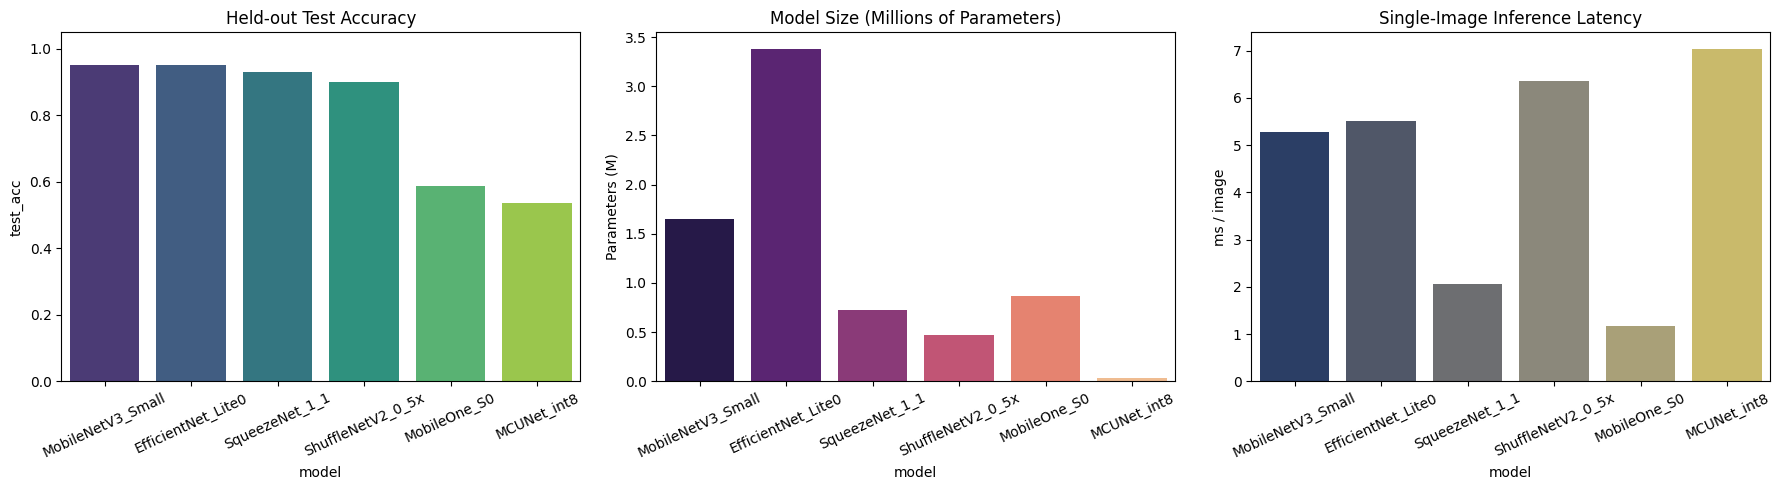

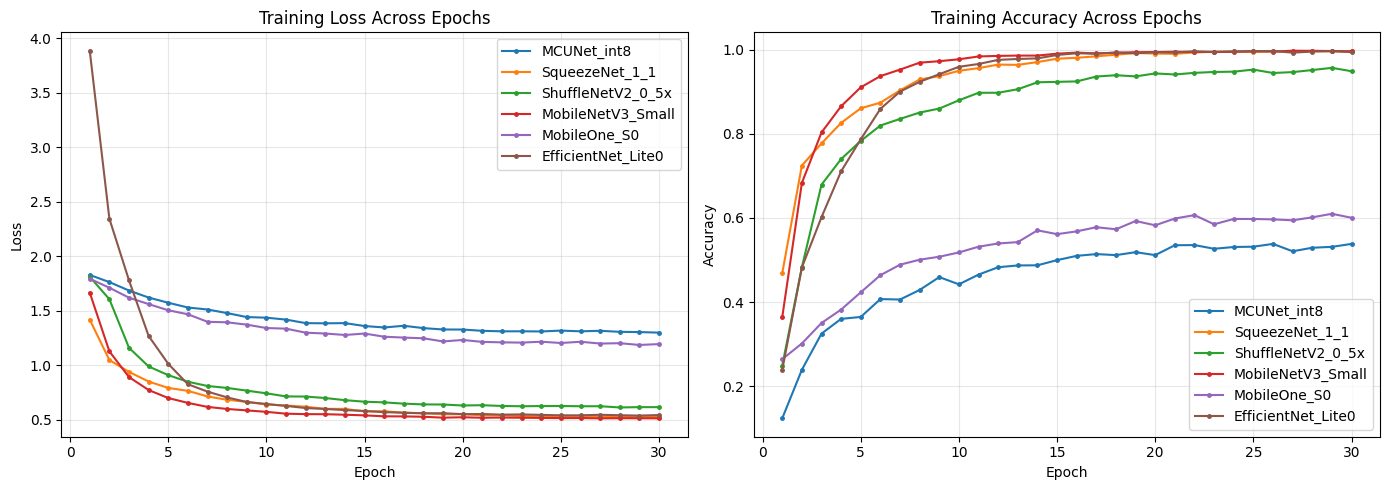

In [8]:
comp_cols = [
    'model', 'eval_device', 'params_M', 'ckpt_size_MB', 'latency_ms_per_img', 'train_time_min',
    'train_acc', 'test_acc', 'test_macro_precision', 'test_macro_recall', 'test_macro_f1', 'test_misclassified'
]
comp_df = pd.DataFrame([all_results[m] for m in MODELS_TO_TRAIN])[comp_cols]
comp_df = comp_df.sort_values(['test_acc', 'test_macro_f1'], ascending=False).reset_index(drop=True)
display(comp_df)
comp_df.to_csv(os.path.join(OUT_DIR, 'edge_models_comparison.csv'), index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=comp_df, x='model', y='test_acc', hue='model', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Held-out Test Accuracy'); axes[0].set_ylim(0, 1.05); axes[0].tick_params(axis='x', rotation=25)

sns.barplot(data=comp_df, x='model', y='params_M', hue='model', palette='magma', legend=False, ax=axes[1])
axes[1].set_title('Model Size (Millions of Parameters)'); axes[1].set_ylabel('Parameters (M)'); axes[1].tick_params(axis='x', rotation=25)

sns.barplot(data=comp_df, x='model', y='latency_ms_per_img', hue='model', palette='cividis', legend=False, ax=axes[2])
axes[2].set_title('Single-Image Inference Latency'); axes[2].set_ylabel('ms / image'); axes[2].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for m_name in MODELS_TO_TRAIN:
    h_df = all_histories[m_name]
    axes[0].plot(range(1, EPOCHS + 1), h_df['train_loss'], marker='o', ms=2.5, label=m_name)
    axes[1].plot(range(1, EPOCHS + 1), h_df['train_acc'], marker='o', ms=2.5, label=m_name)
axes[0].set_title('Training Loss Across Epochs'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].grid(alpha=.3); axes[0].legend()
axes[1].set_title('Training Accuracy Across Epochs'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].grid(alpha=.3); axes[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
#We dropped and skipped  MCUNet_int8 and MobileOne_S0 from research because the custom MobileOne and MCUNet versions in this notebook were random-weight networks trained from scratch, not the real pretrained models, also they underfit badly (54-59% test accuracy) and weren't a fair or citable comparison. so we have called 4 models besides of 6

## 9. Test confusion matrices & per-class F1 breakdown

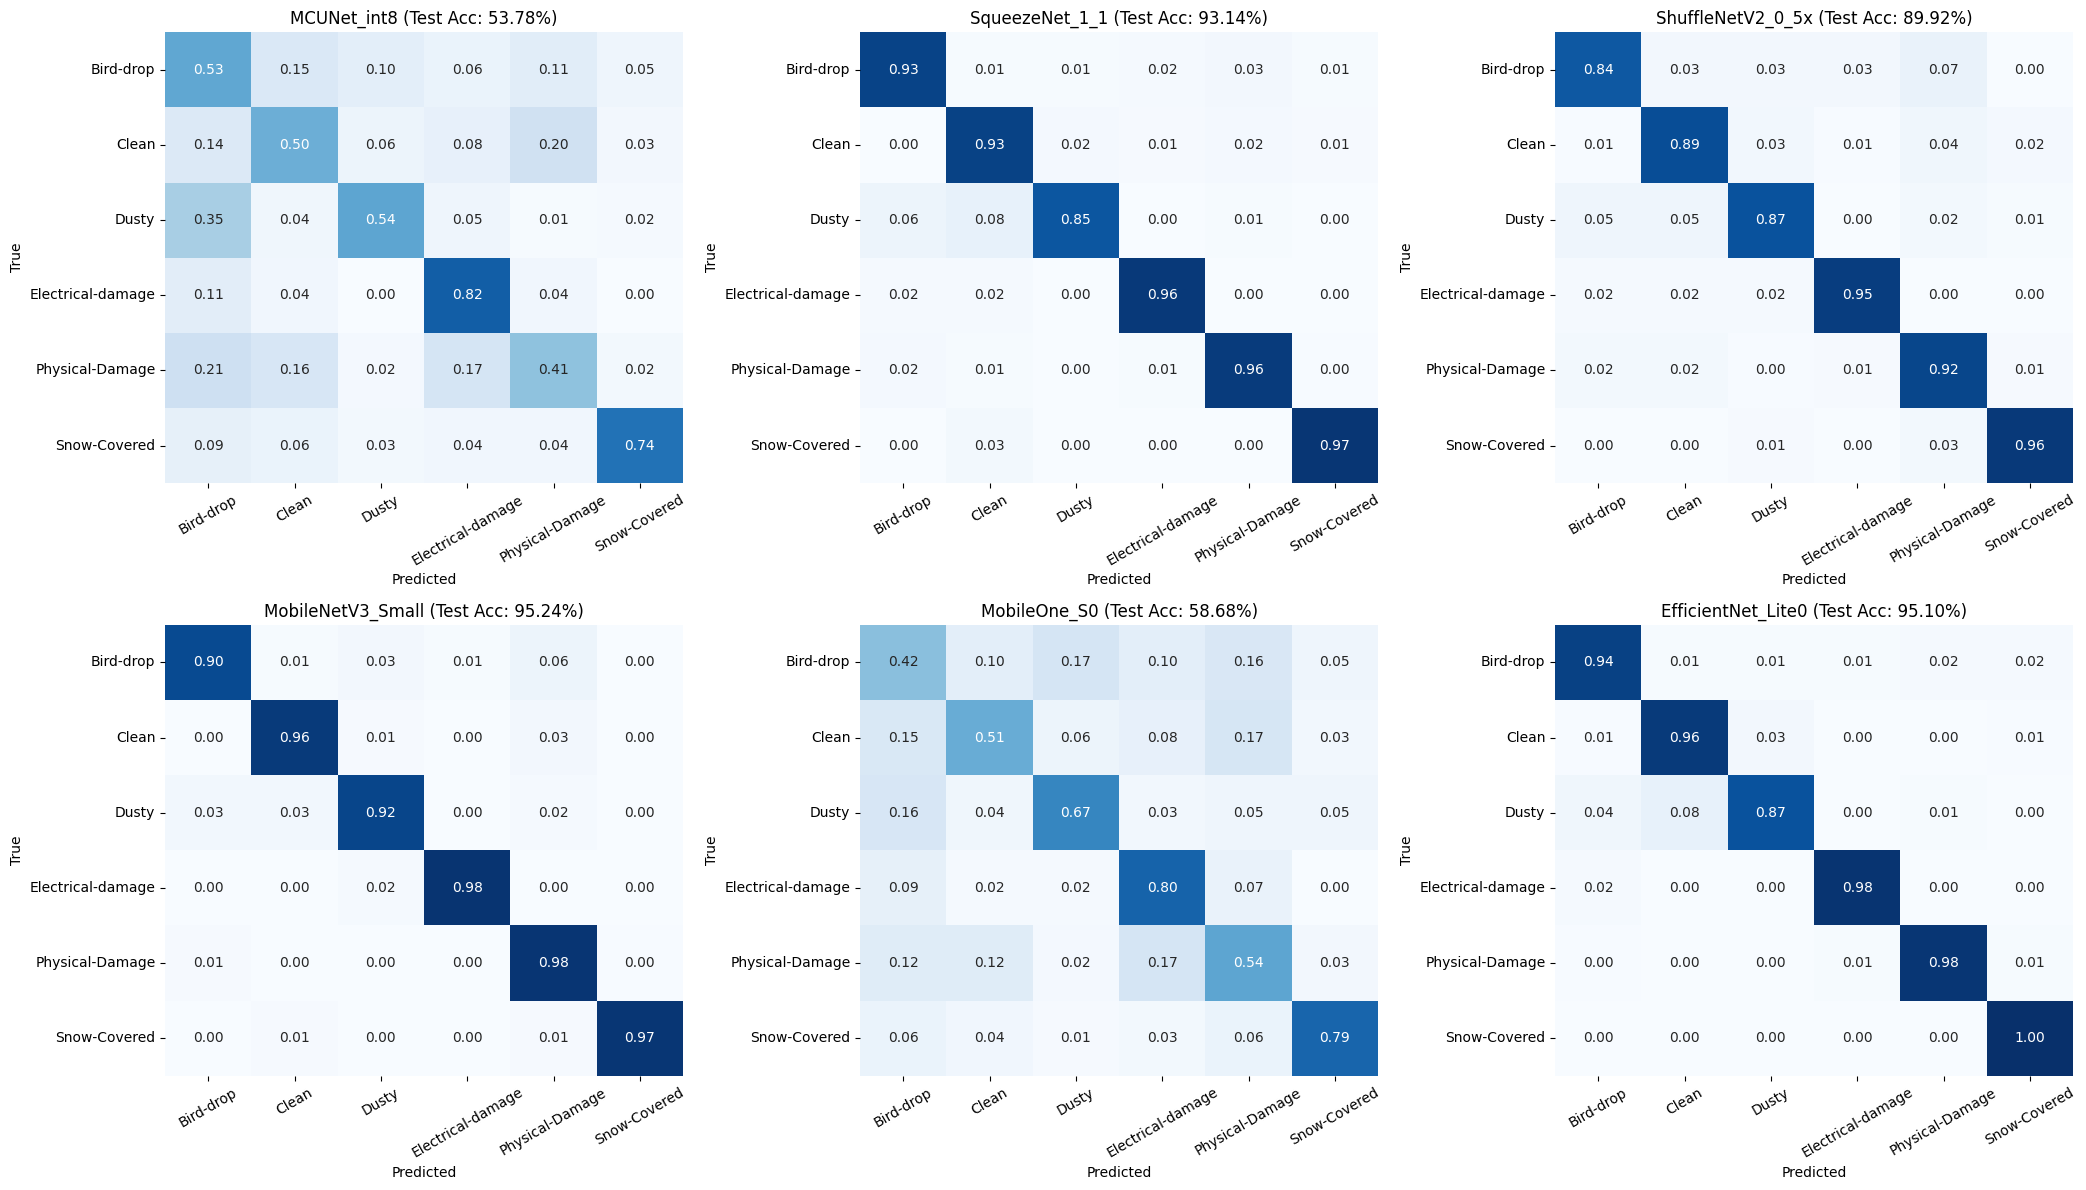

Per-Class Test F1 Across All Six Edge Models:


,Bird-drop,Clean,Dusty,Electrical-damage,Physical-Damage,Snow-Covered
MCUNet_int8,0.4070,0.5180,0.6204,0.5576,0.5000,0.7632
SqueezeNet_1_1,0.9099,0.9122,0.9060,0.9310,0.9602,0.9620
ShuffleNetV2_0_5x,0.8598,0.8927,0.8889,0.9138,0.9113,0.9375
MobileNetV3_Small,0.9159,0.9586,0.9344,0.9821,0.9588,0.9806
MobileOne_S0,0.3983,0.5627,0.6917,0.5455,0.5940,0.7654
EfficientNet_Lite0,0.9315,0.9424,0.9114,0.9649,0.9801,0.9689


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(21, 12))
axes_flat = axes.ravel()
for idx, m_name in enumerate(MODELS_TO_TRAIN):
    _, _, _, cm_te = all_test_preds[m_name]
    cm_norm = cm_te / np.maximum(cm_te.sum(axis=1, keepdims=True), 1)
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes_flat[idx], cbar=False)
    acc_val = all_results[m_name]['test_acc']
    axes_flat[idx].set_title(f'{m_name} (Test Acc: {acc_val:.2%})')
    axes_flat[idx].set_xlabel('Predicted'); axes_flat[idx].set_ylabel('True')
    axes_flat[idx].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

f1_matrix_df = pd.DataFrame({
    m_name: all_results[m_name]['test_f1_per_class'] for m_name in MODELS_TO_TRAIN
}).T
print('Per-Class Test F1 Across All Six Edge Models:')
display(f1_matrix_df)
f1_matrix_df.to_csv(os.path.join(OUT_DIR, 'edge_per_class_f1.csv'))

In [ ]:
#We dropped and skipped  MCUNet_int8 and MobileOne_S0 from research because the custom MobileOne and MCUNet versions in this notebook were random-weight networks trained from scratch, not the real pretrained models, also they underfit badly (54-59% test accuracy) and weren't a fair or citable comparison.

## 10. Save full results JSON

In [10]:
final_payload = {
    'protocol': '80/20 stratified after MD5 + dHash deduplication, no validation set, final-epoch eval',
    'seed': SEED,
    'epochs': EPOCHS,
    'raw_images': int(raw_total),
    'exact_duplicates_removed': int(exact_removed),
    'near_duplicates_removed': int(near_removed),
    'unique_images_after_dedup': int(len(paths)),
    'train_images': int(len(train_paths)),
    'test_images': int(len(test_paths)),
    'models': all_results,
}
json_path = os.path.join(OUT_DIR, 'edge_models_results.json')
with open(json_path, 'w') as f:
    json.dump(final_payload, f, indent=2)
print('Saved full six-model edge comparison results to:', json_path)
print(json.dumps(all_results, indent=2))

Saved full six-model edge comparison results to: /kaggle/working/edge_models_results.json
{
  "MCUNet_int8": {
    "model": "MCUNet_int8",
    "eval_device": "cpu",
    "params_M": 0.0344,
    "params_total": 34406,
    "ckpt_size_MB": 0.118,
    "train_time_min": 11.96,
    "latency_ms_per_img": 7.035,
    "train_acc": 0.5662,
    "train_macro_f1": 0.5818,
    "test_acc": 0.5378,
    "test_macro_precision": 0.5739,
    "test_macro_recall": 0.5908,
    "test_macro_f1": 0.561,
    "test_loss": 1.0958,
    "test_misclassified": 330,
    "test_f1_per_class": {
      "Bird-drop": 0.407,
      "Clean": 0.518,
      "Dusty": 0.6204,
      "Electrical-damage": 0.5576,
      "Physical-Damage": 0.5,
      "Snow-Covered": 0.7632
    }
  },
  "SqueezeNet_1_1": {
    "model": "SqueezeNet_1_1",
    "eval_device": "cuda",
    "params_M": 0.7256,
    "params_total": 725574,
    "ckpt_size_MB": 2.789,
    "train_time_min": 12.28,
    "latency_ms_per_img": 2.061,
    "train_acc": 0.9765,
    "train_mac